# Associations in the training responses

Starts from `processed/train_cleaned.csv`. No predictor in this notebook. The counts in notebook 1 don't show these:

- how tight the side-A rate is, once repeated pairs are kept together
- whether two answers to the same ordered pair agree above chance
- whether swapping the two photos follows the photo or the side
- whether image and cat win rates show up again on a fresh half of the pairs
- whether the background fields go with the side chosen, and with each other

The background fields are nominal, so the association is Cramér's V. Spearman is only for the three fields that have an order.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr

ROOT = Path.cwd()
if not (ROOT / "processed" / "train_cleaned.csv").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEMO_COLS = [
    "gender",
    "pet_history",
    "pet_care",
    "pet_contact",
    "future_pet",
    "mbti_ie",
]
LEVELS = {
    "gender": ["woman", "man"],
    "pet_history": ["current", "past", "never"],
    "pet_care": ["current_regular", "past_regular", "occasionally", "never"],
    "pet_contact": ["daily", "often", "sometimes", "rarely", "never"],
    "future_pet": ["yes", "unsure", "no"],
    "mbti_ie": ["E", "I", "unknown"],
}
ORDINAL = {
    "pet_history": {"current": 2, "past": 1, "never": 0},
    "pet_contact": {"daily": 4, "often": 3, "sometimes": 2, "rarely": 1, "never": 0},
    "future_pet": {"yes": 2, "unsure": 1, "no": 0},
}

rng = np.random.default_rng(21)
train = pd.read_csv(ROOT / "processed" / "train_cleaned.csv")
train["demo_complete"] = train["demo_complete"].astype(bool)
print(f"{len(train):,} rows")

24,896 rows


In [2]:
def wilson_interval(successes, n, z=1.96):
    successes = float(successes)
    n = float(n)
    p = successes / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - margin, centre + margin


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p_value, dof, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return float(v), float(p_value), int(dof)


def cohen_kappa(y1, y2):
    y1 = np.asarray(y1)
    y2 = np.asarray(y2)
    observed = np.mean(y1 == y2)
    expected = np.mean(y1) * np.mean(y2) + (1 - np.mean(y1)) * (1 - np.mean(y2))
    return float((observed - expected) / (1 - expected)), float(observed), float(expected)


def repeated_responses(df):
    ordered = df.sort_values(["ordered_pair_id", "train_row_id"])
    counts = ordered.groupby("ordered_pair_id").size()
    repeated = ordered[ordered["ordered_pair_id"].isin(counts[counts == 2].index)].copy()
    repeated["_k"] = repeated.groupby("ordered_pair_id").cumcount()
    first = repeated[repeated["_k"] == 0].set_index("ordered_pair_id")
    second = repeated[repeated["_k"] == 1].set_index("ordered_pair_id").loc[first.index]
    return first, second


def both_orientations(df):
    grouped = df.groupby(["unordered_pair_id", "ordered_pair_id"], as_index=False).agg(
        chose_a=("chose_a", "mean"),
        n=("chose_a", "size"),
        a_image=("a_image", "first"),
        b_image=("b_image", "first"),
        comparison_type=("comparison_type", "first"),
    )
    n_orient = grouped.groupby("unordered_pair_id").size()
    both = grouped[grouped["unordered_pair_id"].isin(n_orient[n_orient == 2].index)]
    both = both.sort_values(["unordered_pair_id", "a_image"])
    first = both.groupby("unordered_pair_id", as_index=False).nth(0).reset_index(drop=True)
    second = both.groupby("unordered_pair_id", as_index=False).nth(1).reset_index(drop=True)
    return first, second


def side_adjusted(df, id_a, id_b):
    p_side = float(df["chose_a"].mean())
    long = pd.concat(
        [
            pd.DataFrame(
                {
                    "id": df[id_a].to_numpy(),
                    "resid": df["chose_a"].to_numpy() - p_side,
                    "won": df["chose_a"].to_numpy(),
                }
            ),
            pd.DataFrame(
                {
                    "id": df[id_b].to_numpy(),
                    "resid": (1 - df["chose_a"].to_numpy()) - (1 - p_side),
                    "won": 1 - df["chose_a"].to_numpy(),
                }
            ),
        ],
        ignore_index=True,
    )
    scores = long.groupby("id").agg(n=("won", "size"), win_rate=("won", "mean"), resid=("resid", "mean"))
    scores["null_se"] = np.sqrt(p_side * (1 - p_side) / scores["n"])
    return scores, p_side


def split_half_reliability(df, id_a, id_b, min_n, reps):
    """Correlation of side-adjusted strengths when whole pairs are held out.

    Each unordered pair is assigned to one half, so the two orientations of a
    comparison cannot inflate the correlation by landing in different halves.
    """
    pairs = df["unordered_pair_id"].unique()
    correlations = []
    kept = []
    for _ in range(reps):
        chosen = set(rng.choice(pairs, size=len(pairs) // 2, replace=False))
        halves = [
            df[df["unordered_pair_id"].isin(chosen)],
            df[~df["unordered_pair_id"].isin(chosen)],
        ]
        scores = [side_adjusted(half, id_a, id_b)[0] for half in halves]
        joined = scores[0].join(scores[1], lsuffix="_1", rsuffix="_2")
        joined = joined[(joined["n_1"] >= min_n) & (joined["n_2"] >= min_n)]
        kept.append(len(joined))
        if len(joined) > 30:
            correlations.append(float(np.corrcoef(joined["resid_1"], joined["resid_2"])[0, 1]))
    return float(np.mean(correlations)), float(np.std(correlations, ddof=1)), int(np.median(kept))

## Side A

Wilson treats every row as its own draw. The bootstrap resamples unordered pairs, so the two showings of the same photos stay together.

In [3]:
k_a = int(train["chose_a"].sum())
n_rows = len(train)
p_a = k_a / n_rows
wilson_lo, wilson_hi = wilson_interval(k_a, n_rows)

pair_totals = train.groupby("unordered_pair_id")["chose_a"].agg(["sum", "count"])
sums = pair_totals["sum"].to_numpy()
counts = pair_totals["count"].to_numpy()
draw = rng.integers(0, len(pair_totals), size=(2000, len(pair_totals)))
boot = sums[draw].sum(axis=1) / counts[draw].sum(axis=1)
boot_lo, boot_hi = np.quantile(boot, [0.025, 0.975])

side_summary = pd.DataFrame(
    {
        "estimate": [p_a, p_a],
        "low_95": [wilson_lo, boot_lo],
        "high_95": [wilson_hi, boot_hi],
    },
    index=["Wilson, rows independent", "Bootstrap, pairs clustered"],
)
display(side_summary.round(4))
print(f"P(choose A) = {p_a:.4f}")
print(f"Wilson {wilson_lo:.4f} to {wilson_hi:.4f}")
print(f"pair bootstrap {boot_lo:.4f} to {boot_hi:.4f}")

,estimate,low_95,high_95
"Wilson, rows independent",0.519,0.5128,0.5252
"Bootstrap, pairs clustered",0.519,0.5133,0.5248


P(choose A) = 0.5190
Wilson 0.5128 to 0.5252
pair bootstrap 0.5133 to 0.5248


## Agreement on a repeated ordered pair

Cohen's kappa on ordered pairs that were answered twice. The two rows are two responses, not one tracked person. Kappa is how far the match rate sits above the match you'd expect from the overall share of A.

,pairs,observed_agreement,chance_agreement,kappa
subset,,,,
all repeated pairs,9733,0.557,0.501,0.114
within_cat,983,0.525,0.500,0.050
between_cats,8750,0.561,0.501,0.121


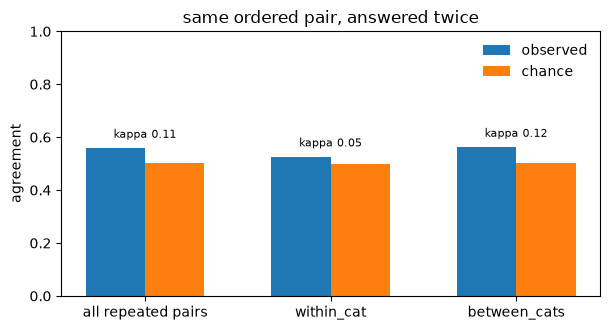

In [4]:
first, second = repeated_responses(train)
agreement_rows = []
for label, mask in [
    ("all repeated pairs", np.ones(len(first), dtype=bool)),
    ("within_cat", first["comparison_type"].eq("within_cat").to_numpy()),
    ("between_cats", first["comparison_type"].eq("between_cats").to_numpy()),
]:
    kappa, observed, expected = cohen_kappa(first.loc[mask, "chose_a"], second.loc[mask, "chose_a"])
    agreement_rows.append(
        {
            "subset": label,
            "pairs": int(mask.sum()),
            "observed_agreement": observed,
            "chance_agreement": expected,
            "kappa": kappa,
        }
    )
agreement = pd.DataFrame(agreement_rows).set_index("subset")
display(agreement.round(3))

fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(len(agreement))
ax.bar(x - 0.16, agreement["observed_agreement"], width=0.32, color="C0", label="observed")
ax.bar(x + 0.16, agreement["chance_agreement"], width=0.32, color="C1", label="chance")
ax.set_xticks(x, agreement.index, rotation=0)
ax.set_ylim(0, 1)
ax.set_ylabel("agreement")
for i, row in enumerate(agreement.itertuples()):
    ax.text(i, row.observed_agreement + 0.03, f"kappa {row.kappa:.2f}", ha="center", va="bottom", fontsize=8)
ax.legend(frameon=False)
ax.set_title("same ordered pair, answered twice")
fig.tight_layout()
fig.savefig(FIG_DIR / "agreement_kappa.png", bbox_inches="tight")
plt.show()

## Swapping the photos

Unordered pairs that were shown both ways. Each order is summarised by its mean of `chose_a`. A negative correlation means the answer followed the photo when the sides flipped. A positive one would mean it followed the side.

Means of 0.5 are ties, and they are left out of the same-image rate. On the pairs where both orders have a winner, same-image and same-side are the only two possibilities, so those two rates add to 1.

,pairs,corr_chose_a,decisive_pairs,same_image,same_side
subset,,,,,
all both-order pairs,7114,-0.138,3639,0.595,0.405
within_cat,888,-0.068,521,0.545,0.455
between_cats,6226,-0.149,3118,0.604,0.396


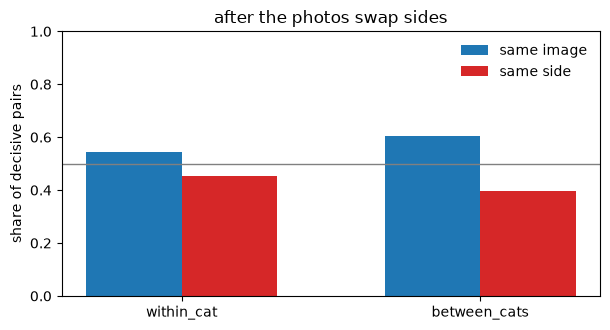

In [5]:
orient_a, orient_b = both_orientations(train)
assert orient_a["unordered_pair_id"].equals(orient_b["unordered_pair_id"])

decisive = (orient_a["chose_a"] != 0.5) & (orient_b["chose_a"] != 0.5)
winner_a = np.where(orient_a["chose_a"] > 0.5, orient_a["a_image"], orient_a["b_image"])
winner_b = np.where(orient_b["chose_a"] > 0.5, orient_b["a_image"], orient_b["b_image"])
same_image = winner_a == winner_b
same_side = ((orient_a["chose_a"] > 0.5) & (orient_b["chose_a"] > 0.5)) | (
    (orient_a["chose_a"] < 0.5) & (orient_b["chose_a"] < 0.5)
)

reversal_rows = []
for label, mask in [
    ("all both-order pairs", np.ones(len(orient_a), dtype=bool)),
    ("within_cat", orient_a["comparison_type"].eq("within_cat").to_numpy()),
    ("between_cats", orient_a["comparison_type"].eq("between_cats").to_numpy()),
]:
    correlation = float(np.corrcoef(orient_a.loc[mask, "chose_a"], orient_b.loc[mask, "chose_a"])[0, 1])
    decided = decisive.to_numpy() & mask
    reversal_rows.append(
        {
            "subset": label,
            "pairs": int(mask.sum()),
            "corr_chose_a": correlation,
            "decisive_pairs": int(decided.sum()),
            "same_image": float(same_image[decided].mean()),
            "same_side": float(same_side.to_numpy()[decided].mean()),
        }
    )
reversal = pd.DataFrame(reversal_rows).set_index("subset")
display(reversal.round(3))

plot_reversal = reversal.loc[["within_cat", "between_cats"]]
fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(len(plot_reversal))
ax.bar(x - 0.16, plot_reversal["same_image"], width=0.32, color="C0", label="same image")
ax.bar(x + 0.16, plot_reversal["same_side"], width=0.32, color="C3", label="same side")
ax.axhline(0.5, color="0.5", lw=1)
ax.set_xticks(x, plot_reversal.index)
ax.set_ylim(0, 1)
ax.set_ylabel("share of decisive pairs")
ax.legend(frameon=False, loc="upper right")
ax.set_title("after the photos swap sides")
fig.tight_layout()
fig.savefig(FIG_DIR / "reversal_consistency.png", bbox_inches="tight")
plt.show()

## Do the win rates replicate?

A raw win rate has the side mixed in: a photo that sits on the left more often wins more often. The residual subtracts the overall side rate. The null standard error is the spread expected if every image were equal and only the side and the sample size mattered.

The signal ratio is the mean squared residual divided by the mean squared null error. Near 1, the apparent winners are sampling noise. The split-half correlation cuts the unordered pairs in two and checks whether strengths from one half line up with the other.

Within-cat rows are two photos of one cat. Between-cat rows mix the cat and the photo. The cat score uses between-cat rows only and pools that cat's photos.

,units,median_appearances,signal_ratio,outside_2se,split_half_r,split_half_sd,units_in_both_halves
unit,,,,,,,
"images, all rows",1296,39.0,2.472,0.223,0.365,0.019,1251
"images, within_cat",1251,5.0,1.156,0.062,0.153,0.067,180
"images, between_cats",1296,34.0,2.502,0.231,0.363,0.010,1249
"cats, between_cats",237,186.0,6.650,0.418,0.694,0.022,237


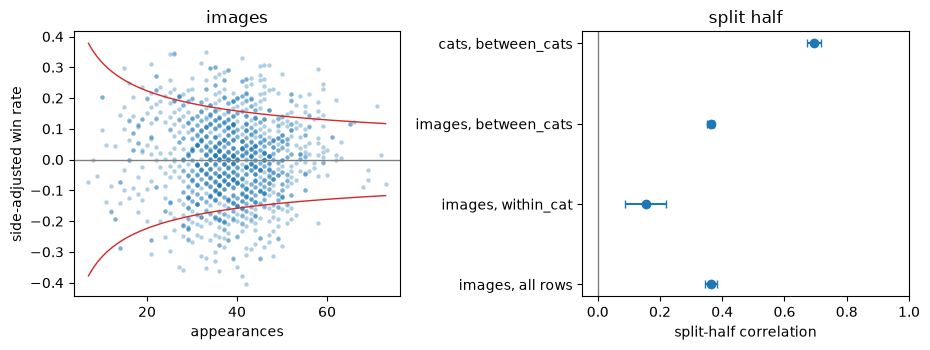

In [6]:
strength_specs = [
    ("images, all rows", train, "a_image", "b_image", 5, 40),
    ("images, within_cat", train[train["comparison_type"] == "within_cat"], "a_image", "b_image", 3, 30),
    ("images, between_cats", train[train["comparison_type"] == "between_cats"], "a_image", "b_image", 4, 30),
    ("cats, between_cats", train[train["comparison_type"] == "between_cats"], "a_cat", "b_cat", 8, 30),
]

strength_rows = []
score_tables = {}
for label, data, id_a, id_b, min_n, reps in strength_specs:
    scores, _ = side_adjusted(data, id_a, id_b)
    score_tables[label] = scores
    signal = float((scores["resid"] ** 2).mean() / (scores["null_se"] ** 2).mean())
    reliability, reliability_sd, n_kept = split_half_reliability(data, id_a, id_b, min_n, reps)
    strength_rows.append(
        {
            "unit": label,
            "units": len(scores),
            "median_appearances": float(scores["n"].median()),
            "signal_ratio": signal,
            "outside_2se": float((scores["resid"].abs() > 2 * scores["null_se"]).mean()),
            "split_half_r": reliability,
            "split_half_sd": reliability_sd,
            "units_in_both_halves": n_kept,
        }
    )
strength = pd.DataFrame(strength_rows).set_index("unit")
display(strength.round(3))

image_scores = score_tables["images, all rows"]
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))
axes[0].scatter(image_scores["n"], image_scores["resid"], s=10, alpha=0.35, color="C0", linewidths=0)
grid = np.linspace(image_scores["n"].min(), image_scores["n"].max(), 200)
band = 2 * np.sqrt(p_a * (1 - p_a) / grid)
axes[0].plot(grid, band, color="C3", lw=1)
axes[0].plot(grid, -band, color="C3", lw=1)
axes[0].axhline(0, color="0.5", lw=1)
axes[0].set_xlabel("appearances")
axes[0].set_ylabel("side-adjusted win rate")
axes[0].set_title("images")

axes[1].errorbar(
    strength["split_half_r"],
    np.arange(len(strength)),
    xerr=strength["split_half_sd"],
    fmt="o",
    color="C0",
    capsize=3,
)
axes[1].axvline(0, color="0.5", lw=1)
axes[1].set_yticks(np.arange(len(strength)), strength.index)
axes[1].set_xlim(-0.05, 1)
axes[1].set_xlabel("split-half correlation")
axes[1].set_title("split half")
fig.tight_layout()
fig.savefig(FIG_DIR / "strength_reliability.png", bbox_inches="tight")
plt.show()

## Background and the side chosen

Association with side A, not with a particular cat. V is 0 when the field and the choice are independent. With about 24,000 rows a very small V can still have a small p-value, so the rate span (highest group rate minus lowest) is the difference in probability.

Pet history, pet care, and pet contact describe overlapping experience. Their V with each other is how redundant they are. Spearman is on the three fields that can be ordered.

,cramers_v,p_value,dof,rate_span
field,,,,
gender,0.0081,0.2082,1,0.0082
pet_history,0.0342,0.0000,2,0.0380
pet_care,0.0257,0.0011,3,0.0339
pet_contact,0.0196,0.0526,4,0.0227
future_pet,0.0317,0.0000,2,0.0392
mbti_ie,0.0478,0.0000,2,0.0534


,spearman_rho,p_value
field,,
pet_history,-0.0323,0.0000
pet_contact,-0.0055,0.3862
future_pet,0.0317,0.0000


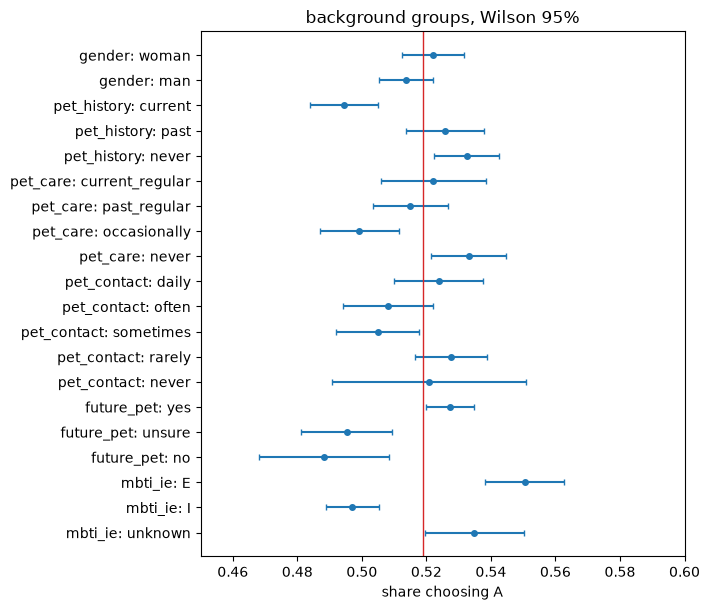

,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
gender,1.00,0.08,0.19,0.20,0.24,0.13
pet_history,0.08,1.00,0.67,0.48,0.13,0.14
pet_care,0.19,0.67,1.00,0.51,0.19,0.12
pet_contact,0.20,0.48,0.51,1.00,0.22,0.23
future_pet,0.24,0.13,0.19,0.22,1.00,0.13
mbti_ie,0.13,0.14,0.12,0.23,0.13,1.00


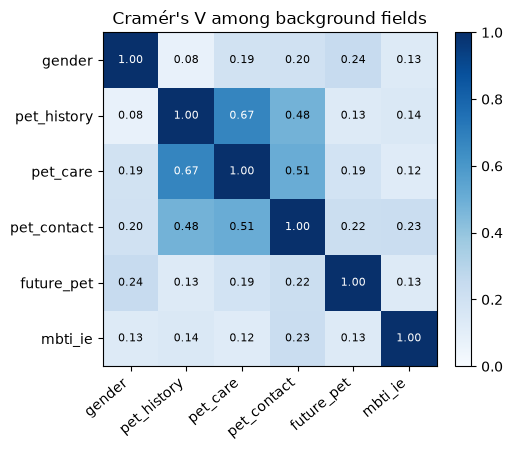

In [7]:
complete = train[train["demo_complete"]].copy()
association_rows = []
rate_rows = []
for col in DEMO_COLS:
    v, p_value, dof = cramers_v(complete[col], complete["choice"])
    rates = complete.groupby(col)["chose_a"].agg(["mean", "sum", "size"])
    association_rows.append(
        {
            "field": col,
            "cramers_v": v,
            "p_value": p_value,
            "dof": dof,
            "rate_span": float(rates["mean"].max() - rates["mean"].min()),
        }
    )
    for level in LEVELS[col]:
        row = rates.loc[level]
        low, high = wilson_interval(row["sum"], row["size"])
        rate_rows.append(
            {
                "label": f"{col}: {level}",
                "rate": row["mean"],
                "low": low,
                "high": high,
                "n": int(row["size"]),
            }
        )

association = pd.DataFrame(association_rows).set_index("field")
display(association.round(4))

rank_rows = []
for col, coding in ORDINAL.items():
    coded = complete[col].map(coding)
    rho, p_value = spearmanr(coded, complete["chose_a"])
    rank_rows.append({"field": col, "spearman_rho": rho, "p_value": p_value})
display(pd.DataFrame(rank_rows).set_index("field").round(4))

rates = pd.DataFrame(rate_rows).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 6.2))
y = np.arange(len(rates))
ax.errorbar(
    rates["rate"],
    y,
    xerr=[rates["rate"] - rates["low"], rates["high"] - rates["rate"]],
    fmt="o",
    color="C0",
    capsize=2,
    markersize=4,
)
ax.axvline(p_a, color="C3", lw=1)
ax.set_yticks(y, rates["label"])
ax.set_xlabel("share choosing A")
ax.set_xlim(0.45, 0.60)
ax.set_title("background groups, Wilson 95%")
fig.tight_layout()
fig.savefig(FIG_DIR / "choice_rate_intervals.png", bbox_inches="tight")
plt.show()

v_matrix = pd.DataFrame(index=DEMO_COLS, columns=DEMO_COLS, dtype=float)
for left in DEMO_COLS:
    for right in DEMO_COLS:
        if left == right:
            v_matrix.loc[left, right] = 1.0
        elif pd.isna(v_matrix.loc[left, right]):
            v, _, _ = cramers_v(complete[left], complete[right])
            v_matrix.loc[left, right] = v
            v_matrix.loc[right, left] = v
display(v_matrix.round(2))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
image = ax.imshow(v_matrix.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(DEMO_COLS)), DEMO_COLS, rotation=40, ha="right")
ax.set_yticks(range(len(DEMO_COLS)), DEMO_COLS)
for i in range(len(DEMO_COLS)):
    for j in range(len(DEMO_COLS)):
        value = float(v_matrix.iloc[i, j])
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value >= 0.55 else "black",
        )
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Cramér's V among background fields")
fig.tight_layout()
fig.savefig(FIG_DIR / "background_cramers_v.png", bbox_inches="tight")
plt.show()

## Blank background rows

The 508 rows kept in cleaning. This checks whether they choose A at the same rate as the complete rows.

In [8]:
missing_rows = []
for label, mask in [
    ("background missing", ~train["demo_complete"]),
    ("background complete", train["demo_complete"]),
]:
    subset = train.loc[mask]
    low, high = wilson_interval(subset["chose_a"].sum(), len(subset))
    missing_rows.append(
        {
            "rows": label,
            "n": len(subset),
            "share_chose_a": subset["chose_a"].mean(),
            "low_95": low,
            "high_95": high,
            "share_within_cat": (subset["comparison_type"] == "within_cat").mean(),
        }
    )
missing_summary = pd.DataFrame(missing_rows).set_index("rows")
display(missing_summary.round(3))

partner_counts = train.groupby("ordered_pair_id")["demo_complete"].agg(["sum", "size"])
one_missing = partner_counts[(partner_counts["size"] == 2) & (partner_counts["sum"] == 1)]
paired = train[train["ordered_pair_id"].isin(one_missing.index)].sort_values(
    ["ordered_pair_id", "train_row_id"]
)
paired["_k"] = paired.groupby("ordered_pair_id").cumcount()
left = paired[paired["_k"] == 0].set_index("ordered_pair_id")
right = paired[paired["_k"] == 1].set_index("ordered_pair_id").loc[left.index]
agree = float(np.mean(left["choice"].to_numpy() == right["choice"].to_numpy()))
blank_cats = pd.unique(train.loc[~train["demo_complete"], ["a_cat", "b_cat"]].values.ravel()).size
blank_ids = train.loc[~train["demo_complete"], "train_row_id"]
print("pairs with one blank and one complete response:", len(one_missing))
print("those two agree:", round(agree, 3))
print("cats on a blank row:", blank_cats)
print("blank ids run from", blank_ids.iloc[0], "to", blank_ids.iloc[-1])

,n,share_chose_a,low_95,high_95,share_within_cat
rows,,,,,
background missing,508,0.604,0.561,0.646,0.096
background complete,24388,0.517,0.511,0.523,0.121


pairs with one blank and one complete response: 401
those two agree: 0.539
cats on a blank row: 234
blank ids run from TR000027 to TR024873


## Reading the numbers

Kappa near 0.1 means a second response mostly fails to reproduce the first. A negative swap correlation, with the same image winning both orders more than half the time, is a photo effect on top of the side. A high cat split-half correlation next to a low within-cat correlation means the part that replicates is which cat. V with `choice` under about 0.10 means that background field barely moves the side rate. The blank rows choose A more often than the complete rows, so they stay in overall rates and stay out of the background breakdowns.

In [9]:
print(f"side A {p_a:.3f}   pair bootstrap 95% {boot_lo:.3f} to {boot_hi:.3f}")
print("kappa")
for idx, row in agreement.iterrows():
    print(f"  {idx}: {row.kappa:.3f}   agreement {row.observed_agreement:.3f}")
print("swap correlation of chose_a")
for idx, row in reversal.iterrows():
    print(f"  {idx}: {row.corr_chose_a:.3f}   same image {row.same_image:.3f}")
print("split-half r")
for idx, row in strength.iterrows():
    print(f"  {idx}: {row.split_half_r:.3f}   sd {row.split_half_sd:.3f}")
print("Cramér's V with choice")
for idx, row in association.iterrows():
    print(f"  {idx}: {row.cramers_v:.3f}")
print(
    "background V  "
    f"history-care {v_matrix.loc['pet_history', 'pet_care']:.2f}  "
    f"care-contact {v_matrix.loc['pet_care', 'pet_contact']:.2f}  "
    f"history-contact {v_matrix.loc['pet_history', 'pet_contact']:.2f}"
)
print(
    f"blank rows choose A at {missing_summary.loc['background missing', 'share_chose_a']:.3f}; "
    f"complete rows at {missing_summary.loc['background complete', 'share_chose_a']:.3f}"
)

side A 0.519   pair bootstrap 95% 0.513 to 0.525
kappa
  all repeated pairs: 0.114   agreement 0.557
  within_cat: 0.050   agreement 0.525
  between_cats: 0.121   agreement 0.561
swap correlation of chose_a
  all both-order pairs: -0.138   same image 0.595
  within_cat: -0.068   same image 0.545
  between_cats: -0.149   same image 0.604
split-half r
  images, all rows: 0.365   sd 0.019
  images, within_cat: 0.153   sd 0.067
  images, between_cats: 0.363   sd 0.010
  cats, between_cats: 0.694   sd 0.022
Cramér's V with choice
  gender: 0.008
  pet_history: 0.034
  pet_care: 0.026
  pet_contact: 0.020
  future_pet: 0.032
  mbti_ie: 0.048
background V  history-care 0.67  care-contact 0.51  history-contact 0.48
blank rows choose A at 0.604; complete rows at 0.517
